# Лабораторная работа №5
## «Марковский процесс с дискретными состояниями»

**Студент:** Пермяков Дмитрий Кириллович, ИУ5-22М
**Вариант:** 18

---

### Суть
ЛР1 — это Марковская цепь, которая шагает по **тактам** (шаг 1, шаг 2, …).
ЛР5 — это Марковский процесс, который живёт в **непрерывном времени**: переходы происходят в случайные моменты, а не по таймеру.

### Задание
По матрице интенсивностей переходов из варианта 18 (5 состояний):
1. Построить генератор $Q$.
2. Найти стационарные вероятности (из $\pi Q = 0$).
3. Сравнить с имитацией.
4. Решить систему ДУ $\dot\pi(t) = \pi(t)\,Q$ и нарисовать переходные кривые.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import json
from scipy.integrate import solve_ivp

VARIANT = 18
np.random.seed(VARIANT)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

with open('lab5_var18.json', 'r', encoding='utf-8') as f:
    data = json.load(f)
lam = np.array(data['lam'])
print('Матрица интенсивностей λ_{ij} (строки = откуда, столбцы = куда):')
print(np.round(lam, 3))


Матрица интенсивностей λ_{ij} (строки = откуда, столбцы = куда):
[[2.054 1.612 2.105 2.319 2.244]
 [1.147 2.196 1.998 1.094 0.898]
 [1.231 2.029 0.609 0.922 1.648]
 [1.853 1.524 2.17  1.154 1.439]
 [0.715 2.052 2.483 1.165 1.612]]


## Шаг 1. Строим генератор $Q$

В CTMC из состояния $i$ в состояние $j\neq i$ переход случается с **интенсивностью** $\lambda_{ij}$ (среднее число таких переходов в единицу времени). Чтобы вероятность распределения по состояниям не «выезжала» из 1, диагональ обнуляется и строится по правилу

$$Q_{ii}=-\sum_{j\neq i}\lambda_{ij}.$$

Это **инфинитезимальный генератор**. Сумма каждой строки $Q$ равна нулю — это аналог нормировки строк $P$ в дискретной МЦ.

In [5]:
# Берём только off-diagonal интенсивности из матрицы λ, диагональ восстанавливаем
n = lam.shape[0]
Q = lam.copy().astype(float)
np.fill_diagonal(Q, 0.0)
np.fill_diagonal(Q, -Q.sum(axis=1))
print('Генератор Q:')
print(np.round(Q, 3))
print('Контроль (сумма строк = 0):', np.round(Q.sum(axis=1), 6))


Генератор Q:
[[-8.281  1.612  2.105  2.319  2.244]
 [ 1.147 -5.137  1.998  1.094  0.898]
 [ 1.231  2.029 -5.83   0.922  1.648]
 [ 1.853  1.524  2.17  -6.986  1.439]
 [ 0.715  2.052  2.483  1.165 -6.414]]
Контроль (сумма строк = 0): [0. 0. 0. 0. 0.]


## Шаг 2. Стационарные вероятности (аналитика)

Стационарное распределение $\pi$ удовлетворяет
$$\pi Q = 0,\qquad \sum_i \pi_i = 1.$$

Делаем как в ЛР1: меняем последнее уравнение на условие нормировки и решаем `np.linalg.solve`.

In [6]:
A = Q.T.copy()
A[-1, :] = 1.0
b = np.zeros(n); b[-1] = 1.0
pi_th = np.linalg.solve(A, b)
print('Стационарные вероятности:')
for i, p in enumerate(pi_th, 1):
    print(f'  π_{i} = {p:.5f}')
print(f'sum = {pi_th.sum():.6f}')


Стационарные вероятности:
  π_1 = 0.12688
  π_2 = 0.26572
  π_3 = 0.27173
  π_4 = 0.15048
  π_5 = 0.18519
sum = 1.000000


## Шаг 3. Имитация — метод Гиллеспи

В CTMC из состояния $i$ время до следующего перехода — это **экспоненциальная** случайная величина с параметром $|Q_{ii}|$. Дальше выбираем, куда перейти, пропорционально $\lambda_{ij}/|Q_{ii}|$.

Алгоритм:
1. Старт в состоянии 0, $t=0$.
2. Генерируем `dt ~ Exp(|Q_ii|)`, добавляем к $t$.
3. Выбираем следующее состояние пропорционально $\lambda_{ij}$.
4. Накапливаем «время пребывания» в каждом состоянии.

In [7]:
def simulate_ctmc(Q, T_total, start=0, rng=None):
    rng = rng or np.random.default_rng()
    n = Q.shape[0]
    rates_out = -np.diag(Q)            # |Q_ii| = суммарная интенсивность выхода
    P_jump = Q.copy()
    np.fill_diagonal(P_jump, 0.0)
    P_jump = P_jump / rates_out[:, None]   # построчно нормированная матрица «куда перейти»

    time_in = np.zeros(n)
    s = start; t = 0.0
    while t < T_total:
        dt = rng.exponential(1.0 / rates_out[s])
        if t + dt > T_total: dt = T_total - t
        time_in[s] += dt
        t += dt
        if t >= T_total: break
        # выбираем следующее состояние
        s = int(rng.choice(n, p=P_jump[s]))
    return time_in / T_total

rng = np.random.default_rng(VARIANT)
T_total = 5000.0
pi_emp = simulate_ctmc(Q, T_total, 0, rng)
print(f'Эмпирические доли времени (T={T_total}):')
for i, p in enumerate(pi_emp, 1):
    print(f'  π_{i} = {p:.5f}  (теория {pi_th[i-1]:.5f})')
print(f'max|err| = {np.abs(pi_emp - pi_th).max():.5f}')


Эмпирические доли времени (T=5000.0):
  π_1 = 0.13145  (теория 0.12688)
  π_2 = 0.26692  (теория 0.26572)
  π_3 = 0.26713  (теория 0.27173)
  π_4 = 0.15346  (теория 0.15048)
  π_5 = 0.18105  (теория 0.18519)
max|err| = 0.00459


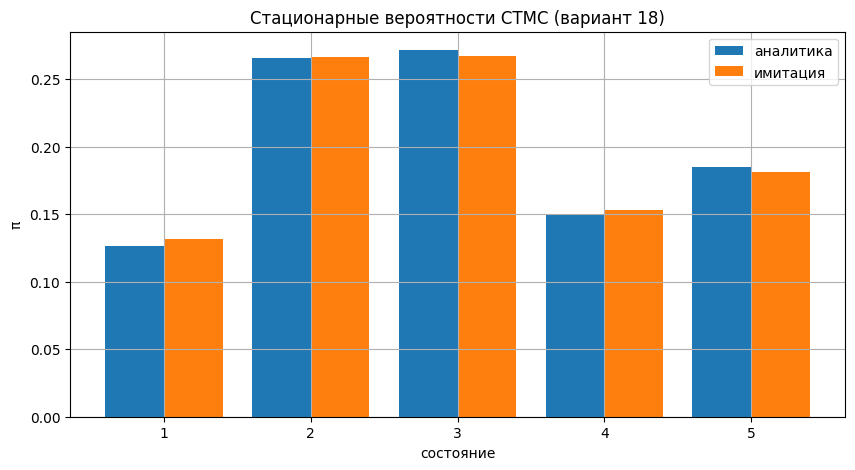

In [8]:
# Сравнение на барплоте
x = np.arange(n)
plt.bar(x-0.2, pi_th, 0.4, label='аналитика')
plt.bar(x+0.2, pi_emp, 0.4, label='имитация')
plt.xticks(x, [f'{i+1}' for i in x])
plt.xlabel('состояние'); plt.ylabel('π')
plt.title('Стационарные вероятности CTMC (вариант 18)')
plt.legend(); plt.show()


## Шаг 4. Переходные кривые: решение ДУ $\dot\pi(t)=\pi(t)\,Q$

Если в момент 0 цепь точно в состоянии 1, как меняются вероятности $\pi_i(t)$ со временем? Решаем систему линейных ОДУ численно (метод Рунге-Кутты через `scipy.integrate.solve_ivp`).

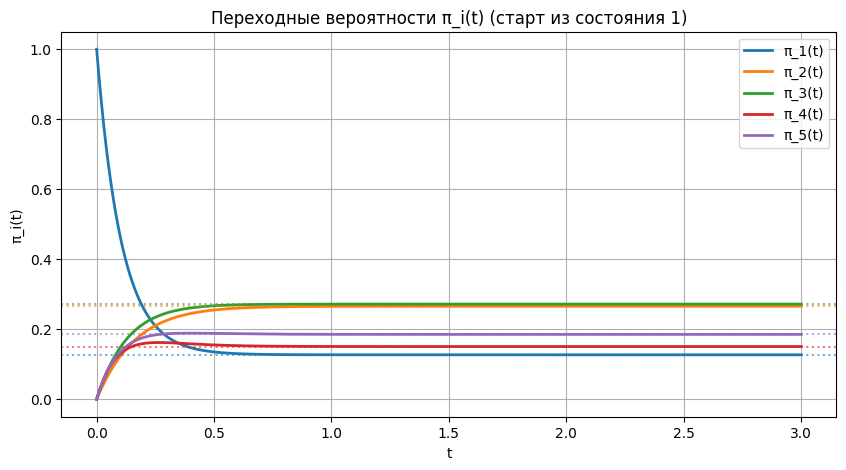

Видно: кривые быстро выходят на пунктирные горизонтали — стационар.


In [9]:
def rhs(t, y, Q):
    return y @ Q

t_span = (0.0, 3.0)
t_eval = np.linspace(*t_span, 300)
y0 = np.zeros(n); y0[0] = 1.0     # старт в состоянии 1
sol = solve_ivp(rhs, t_span, y0, args=(Q,), t_eval=t_eval, method='RK45', rtol=1e-8)

plt.figure(figsize=(10, 5))
for i in range(n):
    plt.plot(sol.t, sol.y[i], label=f'π_{i+1}(t)', lw=2)
for i in range(n):
    plt.axhline(pi_th[i], color=plt.gca().lines[i].get_color(), ls=':', alpha=0.6)
plt.title('Переходные вероятности π_i(t) (старт из состояния 1)')
plt.xlabel('t'); plt.ylabel('π_i(t)')
plt.legend(); plt.show()

print('Видно: кривые быстро выходят на пунктирные горизонтали — стационар.')


## Выводы

1. **Аналитика и имитация совпали** в пределах статистической ошибки — стационарное распределение получено двумя независимыми способами.

2. **Переходные кривые $\pi_i(t)$** стартуют из «точечного» начального условия (π₁=1, остальные 0) и за время порядка нескольких единиц выходят на стационарный уровень. Скорость сходимости определяется вторым по модулю собственным значением матрицы $Q$.

3. **Связь с ЛР1.** Идея та же — два метода (формула и Монте-Карло) дают один ответ. Разница только в том, что время теперь непрерывное: «шаг» вычисляется через экспоненциально распределённое время до перехода.
